In [33]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current working directory:
C:\Users\Chaithanya Reddy\Projects\Wine_Quality_SVM

Files in this folder:
['.ipynb_checkpoints', 'outputs', 'winequality-red.csv', 'Wine_Quality_SVM.ipynb']


In [34]:
import pandas as pd
import numpy as np

# Load the red wine quality dataset
df = pd.read_csv("winequality-red.csv", sep=";")

# Display the first five rows
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [35]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

Dataset shape: (1599, 12)

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non

In [36]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Summary statistics
print("\nStatistical summary:")
df.describe().round(2)

Missing values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate rows: 240

Statistical summary:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00,1599.00
mean,8.32,0.53,0.27,2.54,0.09,15.87,46.47,1.00,3.31,0.66,10.42,5.64
std,1.74,0.18,0.19,1.41,0.05,10.46,32.90,0.00,0.15,0.17,1.07,0.81
min,4.60,0.12,0.00,0.90,0.01,1.00,6.00,0.99,2.74,0.33,8.40,3.00
25%,7.10,0.39,0.09,1.90,0.07,7.00,22.00,1.00,3.21,0.55,9.50,5.00
50%,7.90,0.52,0.26,2.20,0.08,14.00,38.00,1.00,3.31,0.62,10.20,6.00
75%,9.20,0.64,0.42,2.60,0.09,21.00,62.00,1.00,3.40,0.73,11.10,6.00
max,15.90,1.58,1.00,15.50,0.61,72.00,289.00,1.00,4.01,2.00,14.90,8.00


In [37]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

Dataset shape after removing duplicates: (1359, 12)
Remaining duplicate rows: 0
Missing values: 0


In [38]:
# Create binary target
# 0 = Poor, 1 = Good
df["quality_binary"] = (df["quality"] >= 7).astype(int)

# Display class counts
print("Class counts:")
print(df["quality_binary"].value_counts().sort_index().rename(
    index={0: "Poor (0)", 1: "Good (1)"}
))

# Display class percentages
print("\nClass percentages:")
print(
    (df["quality_binary"].value_counts(normalize=True)
     .sort_index() * 100)
    .rename(index={0: "Poor (0)", 1: "Good (1)"})
    .round(2)
)

Class counts:
quality_binary
Poor (0)    1175
Good (1)     184
Name: count, dtype: int64

Class percentages:
quality_binary
Poor (0)    86.46
Good (1)    13.54
Name: proportion, dtype: float64


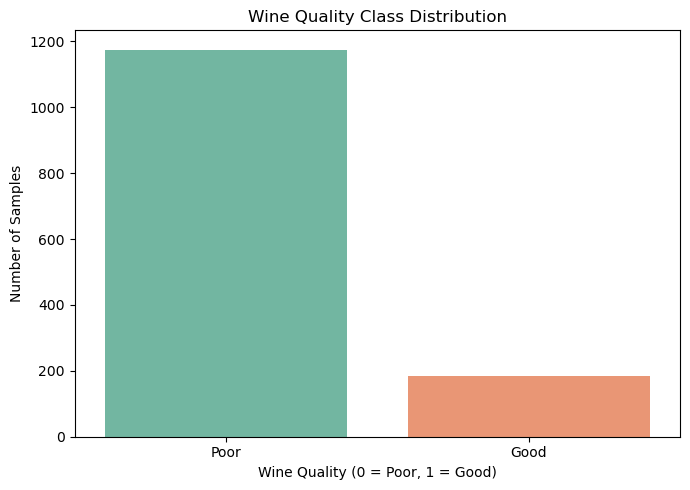

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="quality_binary",
    hue="quality_binary",
    order=[0, 1],
    palette="Set2",
    legend=False
)

plt.title("Wine Quality Class Distribution")
plt.xlabel("Wine Quality (0 = Poor, 1 = Good)")
plt.ylabel("Number of Samples")
plt.xticks([0, 1], ["Poor", "Good"])
plt.tight_layout()
plt.show()

In [40]:
# Check the original quality values after duplicate removal
print("Original quality counts:")
print(df["quality"].value_counts().sort_index())

# Recreate target according to the uploaded project document
df["quality_binary"] = (df["quality"] >= 7).astype(int)

print("\nClass counts (Good = quality >= 7):")
print(df["quality_binary"].value_counts().sort_index())

print("\nClass percentages:")
print(
    (df["quality_binary"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Original quality counts:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

Class counts (Good = quality >= 7):
quality_binary
0    1175
1     184
Name: count, dtype: int64

Class percentages:
quality_binary
0    86.46
1    13.54
Name: proportion, dtype: float64


In [41]:
# Create a new feature by combining the three acidity measurements
df["total_acidity"] = (
    df["fixed acidity"]
    + df["volatile acidity"]
    + df["citric acid"]
)

# Display the original acidity columns and the new feature
df[
    ["fixed acidity", "volatile acidity", "citric acid", "total_acidity"]
].head()

,fixed acidity,volatile acidity,citric acid,total_acidity
0,7.4,0.70,0.00,8.10
1,7.8,0.88,0.00,8.68
2,7.8,0.76,0.04,8.60
3,11.2,0.28,0.56,12.04
4,7.4,0.66,0.00,8.06


In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlations between numerical columns
correlation_matrix = df.corr(numeric_only=True)

# Show correlations with the binary target, excluding the target itself
target_correlation = (
    correlation_matrix["quality_binary"]
    .drop(["quality_binary", "quality"], errors="ignore")
    .sort_values(key=abs, ascending=False)
)

print("Feature correlations with the binary target:")
print(target_correlation.round(3))

Feature correlations with the binary target:
alcohol                 0.410
volatile acidity       -0.267
citric acid             0.204
sulphates               0.202
density                -0.158
total sulfur dioxide   -0.136
fixed acidity           0.116
total_acidity           0.105
chlorides              -0.097
free sulfur dioxide    -0.073
pH                     -0.054
residual sugar          0.053
Name: quality_binary, dtype: float64


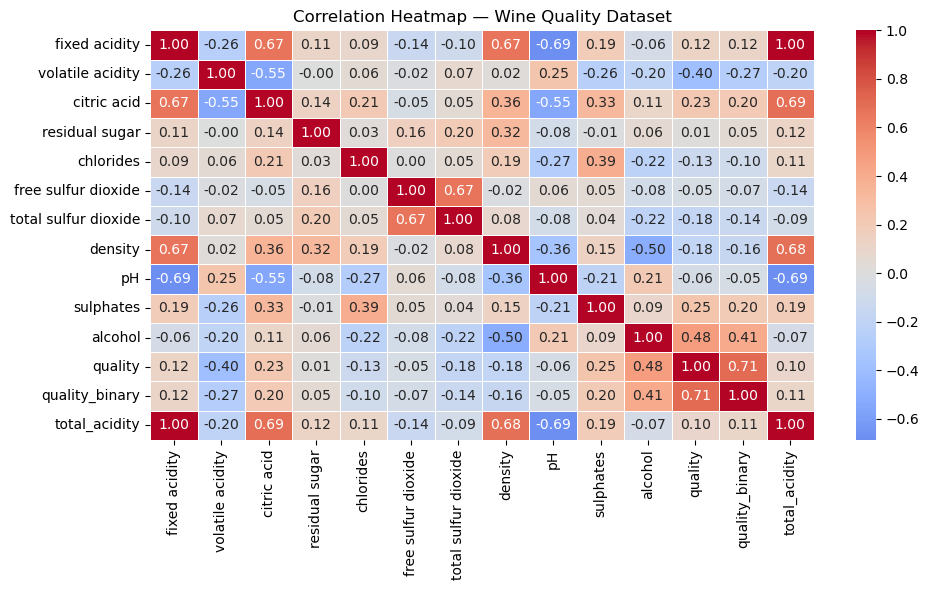

In [43]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap — Wine Quality Dataset")
plt.tight_layout()
plt.show()

In [44]:
# Input features: remove the original score and the binary target
X = df.drop(columns=["quality", "quality_binary"])

# Target: binary wine quality
y = df["quality_binary"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature matrix shape: (1359, 12)
Target shape: (1359,)

Input features:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'total_acidity']

Target distribution:
quality_binary
0    1175
1     184
Name: count, dtype: int64


In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training features: (1087, 12)
Testing features: (272, 12)

Training class proportions:
quality_binary
0    0.865
1    0.135
Name: proportion, dtype: float64

Testing class proportions:
quality_binary
0    0.864
1    0.136
Name: proportion, dtype: float64


In [46]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Build the preprocessing and model pipeline
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model using training data only
svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")
print("Kernel:", svm_model.named_steps["svm"].kernel)
print("C:", svm_model.named_steps["svm"].C)
print("Gamma:", svm_model.named_steps["svm"].gamma)
print("Class weights:", svm_model.named_steps["svm"].class_weight)

SVM model trained successfully!
Kernel: rbf
C: 1.0
Gamma: scale
Class weights: balanced


In [47]:
# Predict wine quality classes for the unseen test set
y_pred = svm_model.predict(X_test)

print("First 20 actual labels:")
print(y_test.iloc[:20].tolist())

print("\nFirst 20 predicted labels:")
print(y_pred[:20].tolist())

print("\nTotal test samples:", len(y_test))
print("Predictions generated:", len(y_pred))

First 20 actual labels:
[0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 20 predicted labels:
[0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0]

Total test samples: 272
Predictions generated: 272


In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

# Display results
print("SVM MODEL EVALUATION")
print("-" * 35)
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Poor (0)", "Good (1)"],
        zero_division=0
    )
)

SVM MODEL EVALUATION
-----------------------------------
Accuracy : 0.7978 (79.78%)
Precision: 0.3816
Recall   : 0.7838
F1-Score : 0.5133

Detailed Classification Report:
              precision    recall  f1-score   support

    Poor (0)       0.96      0.80      0.87       235
    Good (1)       0.38      0.78      0.51        37

    accuracy                           0.80       272
   macro avg       0.67      0.79      0.69       272
weighted avg       0.88      0.80      0.82       272



Confusion Matrix:
[[188  47]
 [  8  29]]

True Negatives  (TN): 188
False Positives (FP): 47
False Negatives (FN): 8
True Positives  (TP): 29


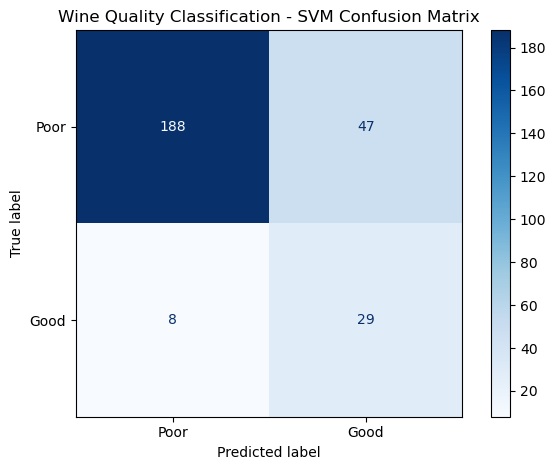

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Keep the label order consistent: Poor = 0, Good = 1
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"\nTrue Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

# Plot the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Poor", "Good"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Wine Quality Classification - SVM Confusion Matrix")
plt.tight_layout()
plt.show()

ROC-AUC Score: 0.8860


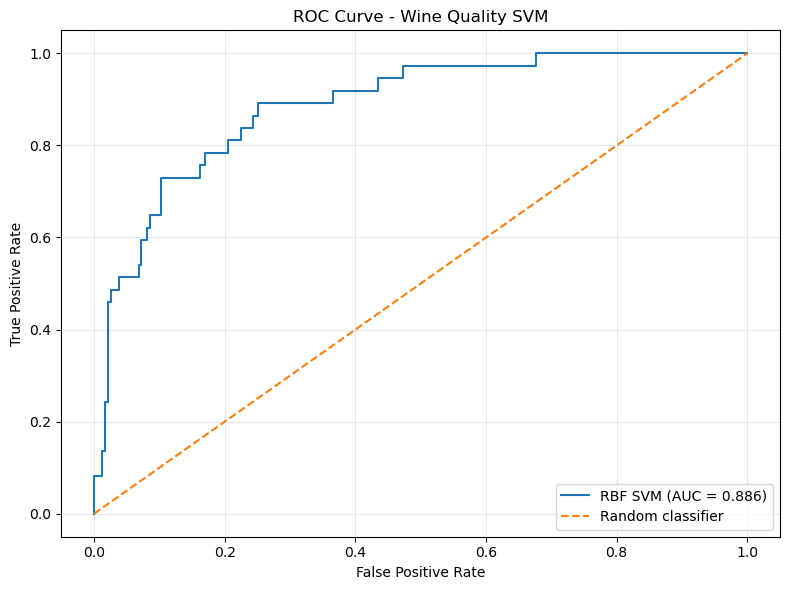

In [50]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Obtain continuous decision scores from the trained SVM
y_scores = svm_model.decision_function(X_test)

# Calculate ROC-AUC
roc_auc = roc_auc_score(y_test, y_scores)

print(f"ROC-AUC Score: {roc_auc:.4f}")

# Calculate points for the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    label=f"RBF SVM (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Wine Quality SVM")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    svm_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Five-fold CV accuracy scores:")
print(cv_scores.round(4))

print(f"\nMean CV accuracy: {cv_scores.mean():.4f}")
print(f"Standard deviation: {cv_scores.std():.4f}")

Five-fold CV accuracy scores:
[0.789  0.8211 0.8111 0.8065 0.8065]

Mean CV accuracy: 0.8068
Standard deviation: 0.0104


In [52]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, make_scorer

# Use F1-score for the Good class (label 1)
f1_scorer = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)

# Calculate permutation importance on the held-out test set
perm_result = permutation_importance(
    svm_model,
    X_test,
    y_test,
    scoring=f1_scorer,
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Organize importance results
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
}).sort_values("Importance Mean", ascending=False)

print("Feature Importance (sorted by F1-score decrease):")
print(importance_df.round(4).to_string(index=False))

Feature Importance (sorted by F1-score decrease):
             Feature  Importance Mean  Importance Std
             alcohol           0.1003          0.0298
           sulphates           0.0717          0.0284
    volatile acidity           0.0264          0.0318
             density           0.0133          0.0224
           chlorides           0.0099          0.0155
         citric acid           0.0034          0.0189
      residual sugar          -0.0009          0.0074
 free sulfur dioxide          -0.0011          0.0113
total sulfur dioxide          -0.0060          0.0251
                  pH          -0.0121          0.0203
       total_acidity          -0.0426          0.0095
       fixed acidity          -0.0508          0.0128


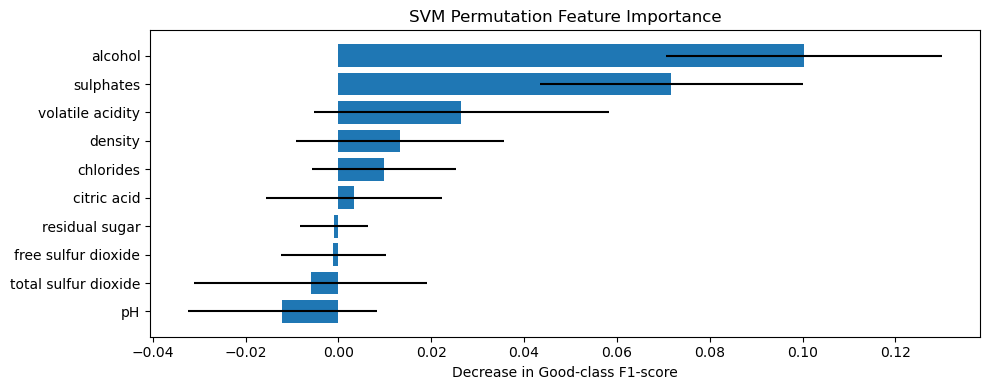

In [53]:
top_features = importance_df.head(10).sort_values("Importance Mean")

plt.figure(figsize=(10, 4))

plt.barh(
    top_features["Feature"],
    top_features["Importance Mean"],
    xerr=top_features["Importance Std"]
)

plt.xlabel("Decrease in Good-class F1-score")
plt.title("SVM Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

kernel_results = []

for kernel_name in ["linear", "rbf", "poly"]:

    # Create a fresh pipeline for each kernel
    candidate_model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel=kernel_name,
            C=1.0,
            gamma="scale",
            class_weight="balanced",
            random_state=42
        ))
    ])

    # Train and predict
    candidate_model.fit(X_train, y_train)
    candidate_pred = candidate_model.predict(X_test)

    # Save evaluation results
    kernel_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_test, candidate_pred),
        "Precision": precision_score(
            y_test, candidate_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, candidate_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, candidate_pred, zero_division=0
        )
    })

kernel_df = pd.DataFrame(kernel_results)

print("SVM Kernel Comparison:")
print(kernel_df.round(4).to_string(index=False))

SVM Kernel Comparison:
Kernel  Accuracy  Precision  Recall  F1-score
linear    0.7831     0.3690  0.8378    0.5124
   rbf    0.7978     0.3816  0.7838    0.5133
  poly    0.8272     0.4138  0.6486    0.5053


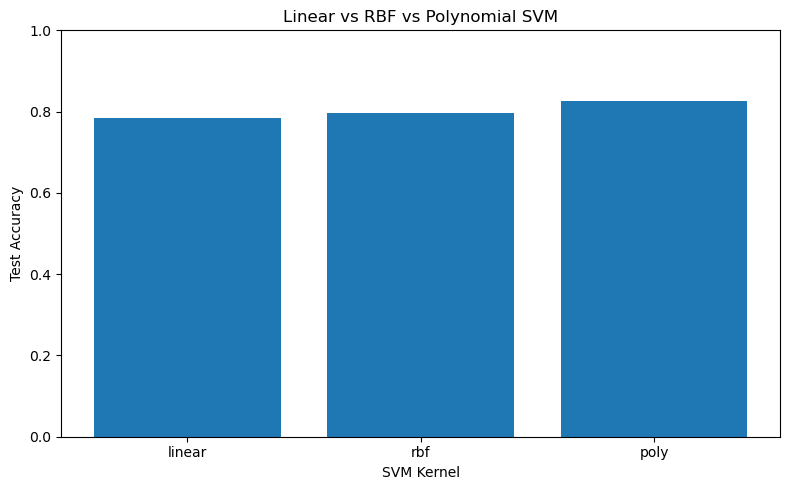

In [55]:
plt.figure(figsize=(8, 5))

plt.bar(
    kernel_df["Kernel"],
    kernel_df["Accuracy"]
)

plt.ylim(0, 1)
plt.xlabel("SVM Kernel")
plt.ylabel("Test Accuracy")
plt.title("Linear vs RBF vs Polynomial SVM")
plt.tight_layout()
plt.show()

In [56]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Save metrics
pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "ROC-AUC": roc_auc,
    "Mean CV Accuracy": cv_scores.mean(),
    "CV Std": cv_scores.std()
}]).to_csv(output_dir / "evaluation_metrics.csv", index=False)

# Save kernel and feature importance tables
kernel_df.to_csv(output_dir / "kernel_comparison.csv", index=False)
importance_df.to_csv(output_dir / "permutation_importance.csv", index=False)

# Save actual and predicted labels
prediction_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
}, index=y_test.index)

prediction_df.to_csv(output_dir / "predictions.csv", index=True)

print("Results saved to:", output_dir.resolve())

Results saved to: C:\Users\Chaithanya Reddy\Projects\Wine_Quality_SVM\outputs


In [57]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

# Save evaluation metrics
metrics_df = pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_score": f1,
    "ROC_AUC": roc_auc,
    "Mean_CV_Accuracy": cv_scores.mean(),
    "CV_Standard_Deviation": cv_scores.std()
}])

metrics_df.to_csv(output_dir / "evaluation_metrics.csv", index=False)

# Save tables
kernel_df.to_csv(output_dir / "kernel_comparison.csv", index=False)
importance_df.to_csv(output_dir / "permutation_importance.csv", index=False)

pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
}, index=y_test.index).to_csv(output_dir / "predictions.csv")

# Save existing plots by recreating them
# Confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Poor", "Good"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.savefig(output_dir / "confusion_matrix.png", dpi=160)
plt.close()

# ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"RBF SVM (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "roc_curve.png", dpi=160)
plt.close()

# Kernel comparison
plt.figure(figsize=(8, 5))
plt.bar(kernel_df["Kernel"], kernel_df["Accuracy"])
plt.ylim(0, 1)
plt.xlabel("SVM Kernel")
plt.ylabel("Test Accuracy")
plt.title("SVM Kernel Comparison")
plt.tight_layout()
plt.savefig(output_dir / "kernel_comparison.png", dpi=160)
plt.close()

print("Saved project outputs to:", output_dir.resolve())
print("\nFiles:")
for file in sorted(output_dir.iterdir()):
    print(file.name)

Saved project outputs to: C:\Users\Chaithanya Reddy\Projects\Wine_Quality_SVM\outputs

Files:
confusion_matrix.png
evaluation_metrics.csv
kernel_comparison.csv
kernel_comparison.png
permutation_importance.csv
predictions.csv
roc_curve.png


# Conclusion

The Wine Quality Classification project successfully implemented Support Vector Machine algorithms to classify red wine into Poor and Good categories using physicochemical features. The dataset initially contained 1,599 records, and 240 duplicate rows were removed, leaving 1,359 records for modeling. Wine samples with quality scores of 7 or above were labeled Good (1), while the remaining samples were labeled Poor (0).

The RBF SVM model was trained using StandardScaler, stratified train-test splitting, and balanced class weights to address differences in feature scales and class distribution. On the test set, the RBF model achieved 79.78% accuracy, 38.16% precision, 78.38% recall, and an F1-score of 51.33% for the Good class. The ROC-AUC score was 0.886, while five-fold cross-validation produced a mean accuracy of 80.68% with a standard deviation of 0.0104.

Among the evaluated kernels, the Polynomial SVM achieved the highest test accuracy of 82.72%, while the RBF SVM achieved the highest Good-class F1-score of 51.33%. Permutation importance identified alcohol and sulphates as the most influential features for the fitted RBF model under the selected evaluation metric.

The results demonstrate that SVM can learn useful patterns in wine-quality data, but the low precision for the Good class indicates that many Poor wines were incorrectly predicted as Good. Further improvement could involve hyperparameter tuning, careful feature selection, and evaluation using class-sensitive metrics. Overall, the project demonstrates the complete machine-learning workflow from data preprocessing through model evaluation and comparison.
